In [1]:
import pandas as pd, numpy as np, scipy.stats as st
import statsmodels.formula.api as smf, statsmodels.api as sm
import matplotlib.pyplot as plt
# import data
df = pd.read_excel("TeamStats.xlsx")
d = df.loc[:, "#Bat":"CS/G"]

### 1)

In [2]:
# calculate the number of observations
n = d.count()
# calculate the standard error of the skew and kurtosis
se_s = np.sqrt(6*n*(n-1)/((n-2)*(n+1)*(n+3)))
se_k = 2*se_s*np.sqrt((n**2-1)/((n-3)*(n+5)))
# calculate the descriptive statistics
t = pd.DataFrame({"N": n, "Min": d.min(), "Max": d.max(), "Mean": d.mean(), "SD": d.std(),
    "Skew": d.apply(lambda c: st.skew(c.dropna(), bias=False)), "SE Skew": se_s,
    "Kurt": d.apply(lambda c: st.kurtosis(c.dropna(), bias=False)), "SE Kurt": se_k})
t["Normal?"] = (t.Skew.abs() < 2*t["SE Skew"]) & (t.Kurt.abs() < 2*t["SE Kurt"])
display(t.round(3))

,N,Min,Max,Mean,SD,Skew,SE Skew,Kurt,SE Kurt,Normal?
#Bat,636,34.000,71.000,47.385,5.588,0.535,0.097,0.507,0.194,False
BatAge,636,24.800,33.500,28.707,1.359,0.354,0.097,0.226,0.194,False
R/G,636,3.170,6.040,4.566,0.505,0.274,0.097,-0.085,0.194,False
G,636,60.000,163.000,161.799,4.055,-24.998,0.097,628.563,0.194,False
1B/G,636,4.698,7.321,5.826,0.431,0.199,0.097,0.076,0.194,False
2B/G,636,1.241,2.321,1.761,0.176,0.204,0.097,0.143,0.194,False
3B/G,636,0.031,0.377,0.181,0.056,0.474,0.097,0.349,0.194,False
HR/G,636,0.562,1.895,1.074,0.224,0.327,0.097,-0.009,0.194,False
SB/G,636,0.117,1.377,0.575,0.191,0.588,0.097,0.286,0.194,False
CS/G,636,0.062,0.457,0.225,0.067,0.566,0.097,0.422,0.194,False


A variable counts as normal when both the skewness and the kurtosis are smaller than twice their standard errors. Here that cutoff is .194 for skewness and .388 for kurtosis.

None of the ten variables meet it. Every variable has skewness larger than .194. **1B/G** (.199) and **2B/G** (.204) are the closest. Kurtosis is also too large for **#Bat**, **G**, and **CS/G**.

### 2)

In [3]:
# keep 7 variables only to match SPSS output
s = d.iloc[:, :7]
# median, range, and quartiles
q = s.apply(lambda c: pd.Series(np.percentile(c.dropna(), [25, 50, 75], method="weibull"), index=[25, 50, 75]))
t2 = pd.DataFrame({"N": s.count(), "Median": s.median(), "Range": s.max() - s.min(),
    "Q1": q.loc[25], "Q2": q.loc[50], "Q3": q.loc[75]})
display(t2.round(3))

,N,Median,Range,Q1,Q2,Q3
#Bat,636,47.000,37.000,43.000,47.000,51.000
BatAge,636,28.600,8.700,27.800,28.600,29.600
R/G,636,4.540,2.870,4.220,4.540,4.898
G,636,162.000,103.000,162.000,162.000,162.000
1B/G,636,5.818,2.623,5.525,5.818,6.117
2B/G,636,1.753,1.080,1.643,1.753,1.870
3B/G,636,0.179,0.346,0.141,0.179,0.216


### 3)

#### a)

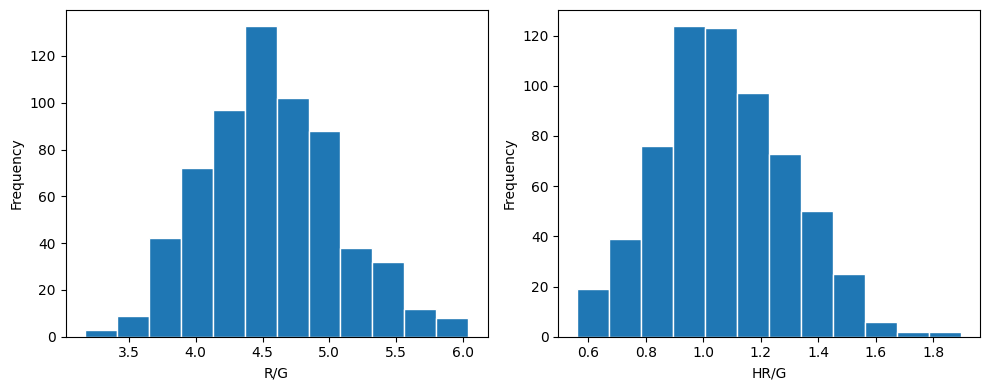

In [4]:
# histograms for R/G and one more variable, HR/G
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ["R/G", "HR/G"]):
    ax.hist(df[col], bins=12, edgecolor="white")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
fig.tight_layout()
plt.show()

R/G has one main peak at 4.5 runs per game. A few teams sit out in the tails near 3.2 and 6. The shape is roughly symmetric, with a slightly longer right tail, so it looks roughly normal.

HR/G has one main peak, near 1.0 home run per game. The right tail is longer, with a few teams near 1.8. It is skewed right, so it is less symmetric than R/G but still roughly normal.

#### b)

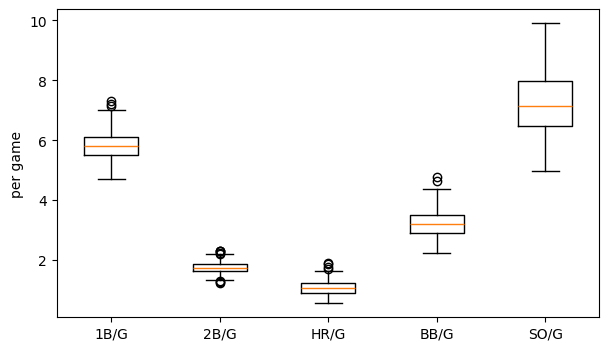

In [5]:
# boxplots of separate variables on one scale
cols = ["1B/G", "2B/G", "HR/G", "BB/G", "SO/G"]
plt.figure(figsize=(7, 4))
plt.boxplot([df[c].dropna() for c in cols], tick_labels=cols)
plt.ylabel("per game")
plt.show()

#### c)

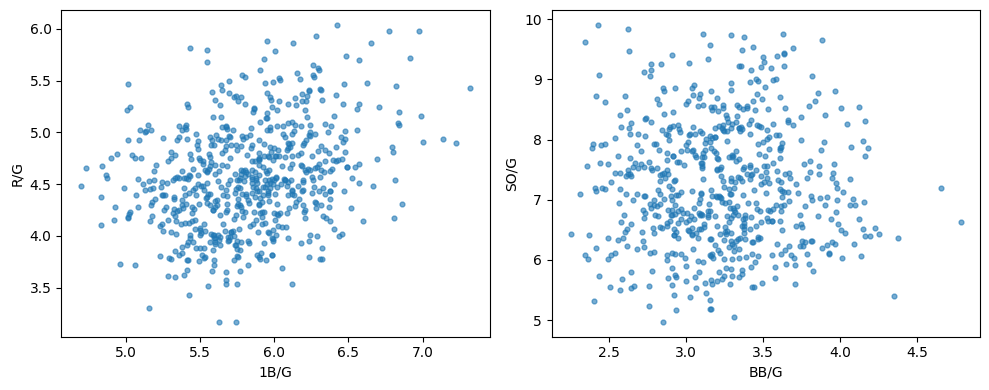

In [6]:
# scatter plots: 1B/G vs R/G, then BB/G vs SO/G
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
pairs = [("1B/G", "R/G"), ("BB/G", "SO/G")]
for ax, (x, y) in zip(axes, pairs):
    ax.scatter(df[x], df[y], s=12, alpha=0.6)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
fig.tight_layout()
plt.show()

### 4)

In [7]:
# Kolmogorov-Smirnov test
from statsmodels.stats.diagnostic import lilliefors
rows = []
for c in d.columns:
    x = d[c].dropna()
    stat, p = lilliefors(x, dist="norm", pvalmethod="approx")
    rows.append({"Statistic": stat, "df": len(x), "Sig.": p})
ks = pd.DataFrame(rows, index=d.columns)
ks["Normal?"] = ks["Sig."] >= 0.05
display(ks.round(3))

,Statistic,df,Sig.,Normal?
#Bat,0.076,636,0.000,False
BatAge,0.068,636,0.000,False
R/G,0.041,636,0.013,False
G,0.452,636,0.000,False
1B/G,0.023,636,0.645,True
2B/G,0.033,636,0.094,True
3B/G,0.049,636,0.001,False
HR/G,0.044,636,0.005,False
SB/G,0.057,636,0.000,False
CS/G,0.060,636,0.000,False


1B/G (Sig. = .645) and 2B/G (Sig. = .094) are not rejected, so those two count as normal by this test. 

### 5)
#### a)

In [8]:
# pairwise Pearson correlations, four variables to match SPSS output
v = ["R/G", "HR/G", "BB/G", "2B/G"]
r = df[v].corr()
p = pd.DataFrame(np.nan, index=v, columns=v)
for a in v:
    for b in v:
        if a != b:
            p.loc[a, b] = st.pearsonr(df[a], df[b])[1]

def sig_cell(x):
    if pd.isna(x):
        return "—"
    if x < 0.0005:
        return ".000"
    s = f"{x:.3f}"
    return s[1:] if s.startswith("0") else s

print("Pearson r")
display(r.round(3))
print("Sig. (2-tailed), N =", len(df))
display(p.map(sig_cell))

Pearson r


,R/G,HR/G,BB/G,2B/G
R/G,1.000,0.660,0.600,0.587
HR/G,0.660,1.000,0.411,0.165
BB/G,0.600,0.411,1.000,0.277
2B/G,0.587,0.165,0.277,1.000


Sig. (2-tailed), N = 636


,R/G,HR/G,BB/G,2B/G
R/G,—,.000,.000,.000
HR/G,.000,—,.000,.000
BB/G,.000,.000,—,.000
2B/G,.000,.000,.000,—


#### b)

In [9]:
def show(frame):
    out = frame.copy()
    for col in out.columns:
        if col == "df":
            continue
        out[col] = out[col].map(lambda x: "" if pd.isna(x) else f"{x:.3f}")
    display(out)

def reg_tables(y, preds, data):
    X = sm.add_constant(data[preds])
    m = sm.OLS(data[y], X).fit()
    anova = pd.DataFrame({
        "SS": [m.ess, m.ssr, m.centered_tss],
        "df": [int(m.df_model), int(m.df_resid), int(m.nobs - 1)],
        "MS": [m.mse_model, m.mse_resid, np.nan],
        "F": [m.fvalue, np.nan, np.nan],
        "Sig.": [m.f_pvalue, np.nan, np.nan],
    }, index=["Regression", "Residual", "Total"])
    beta = m.params * X.std(ddof=1) / data[y].std(ddof=1)
    beta["const"] = np.nan
    coef = pd.DataFrame({"B": m.params, "SE": m.bse, "Beta": beta, "t": m.tvalues, "Sig.": m.pvalues})
    show(anova)
    show(coef.rename(index={"const": "(Constant)"}))
    return m

# R/G on five predictors: singles, doubles, home runs, walks, and strikeouts per game
m5 = reg_tables("R/G", ["1B/G", "2B/G", "HR/G", "BB/G", "SO/G"], df)

,SS,df,MS,F,Sig.
Regression,144.836,5,28.967,1054.058,0.000
Residual,17.313,630,0.027,,
Total,162.150,635,,,


,B,SE,Beta,t,Sig.
(Constant),-2.442,0.196,,-12.449,0.000
1B/G,0.523,0.022,0.446,23.791,0.000
2B/G,0.752,0.043,0.262,17.591,0.000
HR/G,1.462,0.035,0.648,41.630,0.000
BB/G,0.347,0.017,0.295,20.039,0.000
SO/G,-0.007,0.009,-0.014,-0.752,0.452


The model is significant at the 5% level: the ANOVA Sig. is about 0.

SO/G is not significant (Sig. = .452). **1B/G**, **2B/G**, **HR/G**, and **BB/G** are significant.

#### c)

In [10]:
# full model: every variable from #Bat to OPS+, with R/G as the dependent variable
preds = [c for c in df.loc[:, "#Bat":"OPS+"].columns if c != "R/G"]
print("full model")
reg_tables("R/G", preds, df)

# backward elimination: drop the predictor with the largest Sig. until all are below .05
keep = preds[:]
dropped = []
while True:
    p = sm.OLS(df["R/G"], sm.add_constant(df[keep])).fit().pvalues.drop("const")
    if p.max() < 0.05:
        break
    worst = p.idxmax()
    dropped.append({"Variable": worst, "Sig.": p.max()})
    keep.remove(worst)
print("dropped, largest Sig. first")
display(pd.DataFrame(dropped).round(3))
print("final model")
final = reg_tables("R/G", keep, df)

full model


,SS,df,MS,F,Sig.
Regression,159.169,20,7.958,1641.832,0.000
Residual,2.981,615,0.005,,
Total,162.150,635,,,


,B,SE,Beta,t,Sig.
(Constant),-0.193,0.171,,-1.128,0.260
#Bat,0.000,0.001,0.003,0.462,0.644
BatAge,0.003,0.003,0.009,1.273,0.204
G,-0.001,0.001,-0.006,-1.116,0.265
1B/G,0.915,0.014,0.782,65.118,0.000
2B/G,0.946,0.020,0.330,47.065,0.000
3B/G,1.010,0.057,0.111,17.591,0.000
HR/G,1.112,0.019,0.492,57.190,0.000
SB/G,0.023,0.020,0.009,1.184,0.237
CS/G,-0.966,0.059,-0.129,-16.486,0.000


dropped, largest Sig. first


,Variable,Sig.
0,BA,0.735
1,OPS,0.720
2,#Bat,0.612
3,OBP,0.553
4,G,0.272
5,SB/G,0.240
6,BatAge,0.148


final model


,SS,df,MS,F,Sig.
Regression,159.142,13,12.242,2531.506,0.000
Residual,3.008,622,0.005,,
Total,162.150,635,,,


,B,SE,Beta,t,Sig.
(Constant),-0.194,0.103,,-1.883,0.060
1B/G,0.918,0.013,0.784,70.956,0.000
2B/G,0.942,0.019,0.328,48.598,0.000
3B/G,1.004,0.056,0.110,17.818,0.000
HR/G,1.111,0.018,0.492,61.284,0.000
CS/G,-0.943,0.051,-0.126,-18.364,0.000
BB/G,0.886,0.014,0.753,61.487,0.000
SO/G,-0.013,0.004,-0.027,-3.151,0.002
GDP/G,-0.897,0.037,-0.177,-23.976,0.000
HBP/G,0.899,0.035,0.159,25.716,0.000


In the full model, these predictors are not significant at the 5% level: **BA**, **OPS**, **#Bat**, **OBP**, **G**, **SB/G**, **OPS+**, **BatAge**, and **SLG**. The model itself is significant.

Backward elimination then drops the predictor with the largest Sig. and refits. Removed, in order: BA, OPS, #Bat, OBP, G, SB/G, and BatAge. In the final model every predictor has Sig. below .05, and the model is still significant. The intercept is left in, as in the SPSS backward method; its Sig. is .060. SLG and OPS+ were not significant alongside BA, OBP, and OPS, and they become significant after those overlapping variables are removed.